# Market Risk: VaR, Expected Shortfall & Stress Testing

## Objective

This project develops an end-to-end market-risk framework for an equally weighted multi-asset portfolio. It combines portfolio analytics, Value at Risk (VaR), Expected Shortfall (ES), Monte Carlo simulation, volatility modelling, formal VaR backtesting, and historical and hypothetical stress testing.

### Portfolio

| Asset | Ticker | Exposure |
|---|---|---|
| S&P 500 ETF | SPY | Broad US equities |
| Nasdaq-100 ETF | QQQ | Technology/growth equities |
| US Treasury ETF | TLT | Long-duration interest-rate risk |
| Investment Grade Corporate Bond ETF | LQD | Credit and rates |
| Gold ETF | GLD | Commodity / defensive exposure |

The portfolio is assigned an equal **20% weight per asset**. A hypothetical **$1,000,000** portfolio value is used when translating percentage risk measures into dollar losses.

### Headline Findings

- Portfolio returns display negative skewness, substantial excess kurtosis, and pronounced volatility clustering.
- Historical 99% VaR provides the strongest unconditional backtesting performance, with an exception rate close to the theoretical 1% target.
- Gaussian VaR materially understates deeper tail risk and fails formal unconditional-coverage testing.
- EWMA improves volatility responsiveness but does not by itself solve the tail-risk problem.
- A rolling Student-t EWMA model improves on Gaussian EWMA while still failing conditional-coverage testing.
- Historical and hypothetical stress tests show that diversification benefits can weaken sharply when equities and fixed income sell off together.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy import stats

pd.options.display.float_format = "{:,.4f}".format

## 1. Data Acquisition

Adjusted closing prices are downloaded using `yfinance` for the five portfolio ETFs from January 2010 through July 2026.

Using adjusted prices incorporates distributions and corporate actions into the return series. The analysis uses a fixed end date to make the study period explicit; future reruns may produce small differences if the underlying data provider revises historical observations.


In [2]:
tickers = ["SPY", "QQQ", "TLT", "LQD", "GLD"]

start_date = "2010-01-01"
end_date = "2026-08-01"

data = yf.download(
    tickers,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)

prices = data["Close"].dropna()

print(f"Observations: {len(prices):,}")
print(f"Period: {prices.index.min().date()} to {prices.index.max().date()}")

prices.head()

Observations: 4,169
Period: 2010-01-04 to 2026-07-31


Ticker,GLD,LQD,QQQ,SPY,TLT
Date,,,,,
2010-01-04,109.8000,56.9843,40.2466,84.5785,55.2819
2010-01-05,109.7000,57.2564,40.2466,84.8024,55.6389
2010-01-06,111.5100,57.0877,40.0038,84.8621,54.8941
2010-01-07,110.8200,57.1584,40.0298,85.2203,54.9864
2010-01-08,111.3700,57.2836,40.3593,85.5039,54.9618


In [3]:
summary = pd.DataFrame({
    "start": prices.apply(lambda x: x.first_valid_index()),
    "end": prices.apply(lambda x: x.last_valid_index()),
    "observations": prices.count(),
    "missing": prices.isna().sum()
})

summary

,start,end,observations,missing
Ticker,,,,
GLD,2010-01-04,2026-07-31,4169,0
LQD,2010-01-04,2026-07-31,4169,0
QQQ,2010-01-04,2026-07-31,4169,0
SPY,2010-01-04,2026-07-31,4169,0
TLT,2010-01-04,2026-07-31,4169,0


In [4]:
prices.describe().T

,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
GLD,"4,169.0000",166.4809,71.1418,100.5000,121.3900,148.4600,174.9800,495.9000
LQD,"4,169.0000",87.1810,14.7090,56.5572,75.7186,86.6145,99.8836,111.9374
QQQ,"4,169.0000",216.3228,171.7915,36.9519,79.3007,155.0393,323.9617,745.3409
SPY,"4,169.0000",282.6734,172.5668,76.9506,149.6082,234.9954,395.3362,757.6182
TLT,"4,169.0000",91.2523,18.2805,54.4050,81.3897,88.7064,97.9203,142.1270


## 2. Return Construction and Portfolio Statistics

Daily continuously compounded returns are calculated as:

$$
r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)
$$

The portfolio return is approximated as the weighted sum of asset log returns. With daily returns and equal linear exposures this provides a close continuously compounded approximation while retaining convenient additive properties for statistical risk modelling.

Annualised volatility is calculated using 252 trading days. Skewness and excess kurtosis are examined because departures from normality are particularly important for tail-risk measures such as VaR and Expected Shortfall.


In [5]:
returns = np.log(
    prices / prices.shift(1)
).dropna()

returns.head()

Ticker,GLD,LQD,QQQ,SPY,TLT
Date,,,,,
2010-01-05,-0.0009,0.0048,0.0000,0.0026,0.0064
2010-01-06,0.0164,-0.0030,-0.0060,0.0007,-0.0135
2010-01-07,-0.0062,0.0012,0.0007,0.0042,0.0017
2010-01-08,0.0050,0.0022,0.0082,0.0033,-0.0004
2010-01-11,0.0132,0.0010,-0.0041,0.0014,-0.0055


In [6]:
returns.describe().T

,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
GLD,"4,168.0000",0.0003,0.0105,-0.1084,-0.0049,0.0005,0.0057,0.0616
LQD,"4,168.0000",0.0001,0.0048,-0.0513,-0.0021,0.0004,0.0025,0.0713
QQQ,"4,168.0000",0.0007,0.0130,-0.1276,-0.0048,0.0012,0.0074,0.1134
SPY,"4,168.0000",0.0005,0.0108,-0.1159,-0.0037,0.0007,0.0058,0.0999
TLT,"4,168.0000",0.0001,0.0094,-0.0690,-0.0056,0.0005,0.0057,0.0725


In [7]:
weights = pd.Series(
    0.20,
    index=returns.columns,
    name="Weight"
)

assert np.isclose(weights.sum(), 1.0)

portfolio_returns = returns.mul(
    weights,
    axis=1
).sum(axis=1)

print(f"Average daily log return: {portfolio_returns.mean():.4%}")
print(f"Daily volatility: {portfolio_returns.std():.4%}")
print(f"Annualised volatility: {portfolio_returns.std() * np.sqrt(252):.2%}")


Average daily return: 0.0348%
Daily volatility: 0.5899%
Annualised volatility: 9.36%


In [8]:
annualised_return = portfolio_returns.mean() * 252
annualised_volatility = portfolio_returns.std() * np.sqrt(252)

skewness = stats.skew(portfolio_returns)
kurtosis = stats.kurtosis(portfolio_returns)

portfolio_stats = pd.Series({
    "Annualised Mean Log Return": annualised_return,
    "Annualised Volatility": annualised_volatility,
    "Skewness": skewness,
    "Excess Kurtosis": kurtosis,
    "Worst Daily Return": portfolio_returns.min(),
    "Best Daily Return": portfolio_returns.max()
})

portfolio_stats


Annualised Return        0.0876
Annualised Volatility    0.0936
Skewness                -0.3099
Excess Kurtosis          8.5143
Worst Daily Return      -0.0560
Best Daily Return        0.0544
dtype: float64

## 3. Dependence, Volatility and Drawdown Analysis

Before estimating VaR and Expected Shortfall, the portfolio's underlying risk structure is examined through asset correlations, rolling volatility and drawdowns.

Correlation measures diversification across the five market exposures, while rolling volatility captures changes in risk through different market regimes. Drawdown measures peak-to-trough portfolio losses and provides a complementary view of downside risk that is not captured by volatility alone.


In [9]:
correlation_matrix = returns.corr()

correlation_matrix

Ticker,GLD,LQD,QQQ,SPY,TLT
Ticker,,,,,
GLD,1.0000,0.2630,0.0757,0.0691,0.2061
LQD,0.2630,1.0000,0.1966,0.1996,0.6834
QQQ,0.0757,0.1966,1.0000,0.9307,-0.2189
SPY,0.0691,0.1996,0.9307,1.0000,-0.2856
TLT,0.2061,0.6834,-0.2189,-0.2856,1.0000


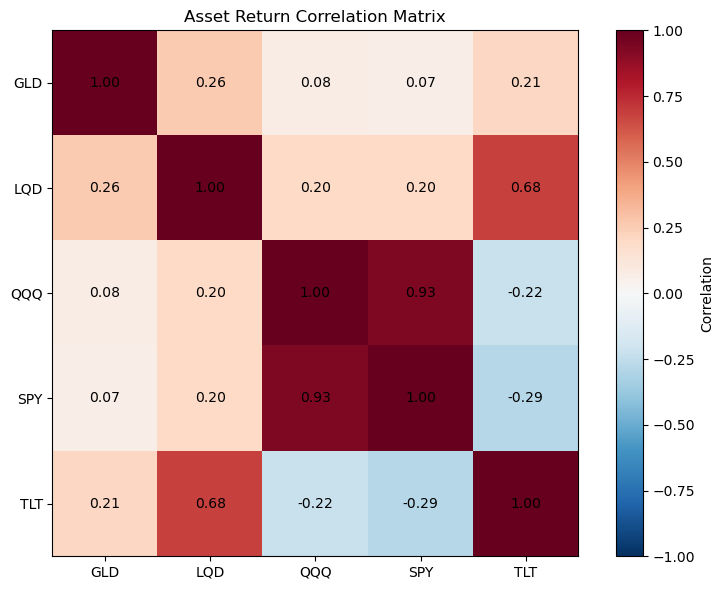

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    correlation_matrix,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.columns)))

ax.set_xticklabels(correlation_matrix.columns)
ax.set_yticklabels(correlation_matrix.columns)

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        ax.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax, label="Correlation")

ax.set_title("Asset Return Correlation Matrix")

plt.tight_layout()
plt.show()

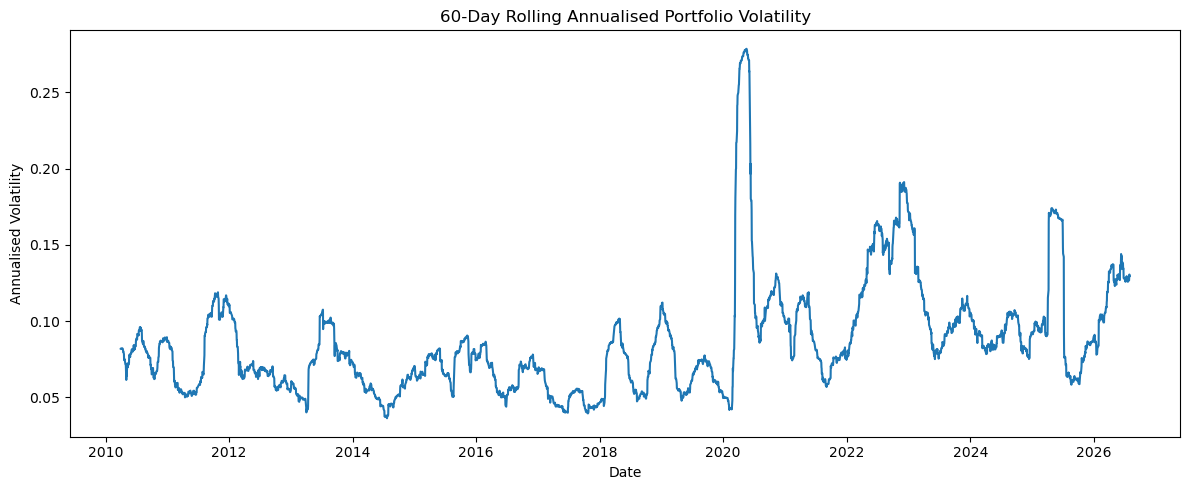

In [11]:
rolling_volatility = (
    portfolio_returns
    .rolling(window=60)
    .std()
    * np.sqrt(252)
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(rolling_volatility)

ax.set_title("60-Day Rolling Annualised Portfolio Volatility")
ax.set_ylabel("Annualised Volatility")
ax.set_xlabel("Date")

plt.tight_layout()
plt.show()

In [12]:
portfolio_value = np.exp(portfolio_returns.cumsum())

running_peak = portfolio_value.cummax()

drawdown = (
    portfolio_value / running_peak
    - 1
)

max_drawdown = drawdown.min()
max_drawdown_date = drawdown.idxmin()

print(f"Maximum drawdown: {max_drawdown:.2%}")
print(f"Maximum drawdown date: {max_drawdown_date.date()}")

Maximum drawdown: -25.53%
Maximum drawdown date: 2022-10-20


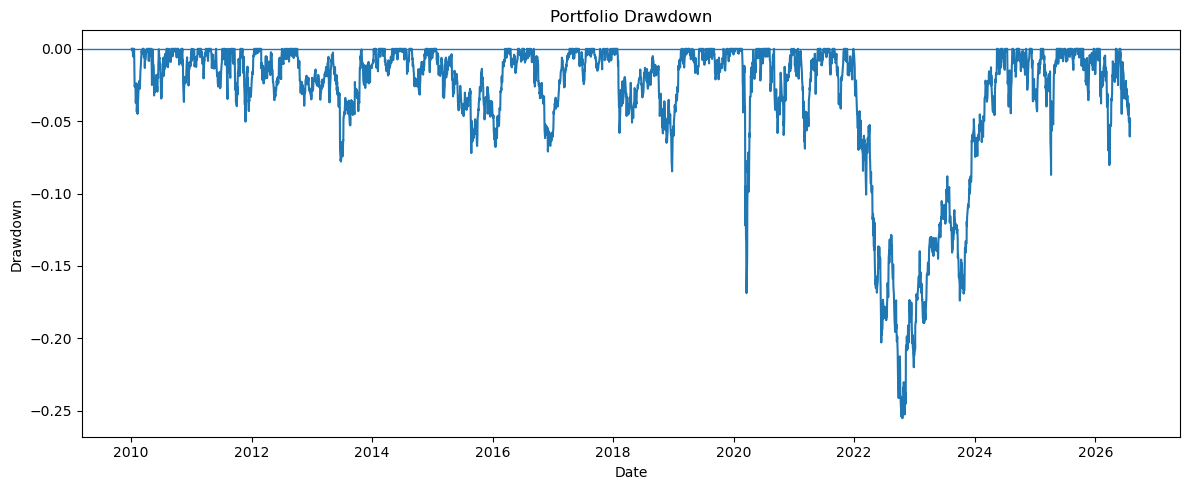

In [13]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(drawdown)

ax.axhline(
    0,
    linewidth=1
)

ax.set_title("Portfolio Drawdown")
ax.set_ylabel("Drawdown")
ax.set_xlabel("Date")

plt.tight_layout()
plt.show()

## 4. Historical Value at Risk and Expected Shortfall

Historical simulation estimates downside risk directly from the empirical distribution of portfolio returns without imposing a parametric distribution.

Value at Risk (VaR) measures the loss threshold exceeded with a specified probability over a given horizon. Expected Shortfall (ES) measures the average loss conditional on exceeding that VaR threshold, providing information about the severity of tail losses.

Both 95% and 99% confidence levels are considered.


In [14]:
confidence_levels = [0.95, 0.99]

historical_results = []

for confidence in confidence_levels:
    
    alpha = 1 - confidence
    
    var = -portfolio_returns.quantile(alpha)
    
    tail_returns = portfolio_returns[
        portfolio_returns <= -var
    ]
    
    es = -tail_returns.mean()
    
    historical_results.append({
        "Confidence Level": confidence,
        "Historical VaR": var,
        "Historical ES": es
    })

historical_risk = pd.DataFrame(historical_results)

historical_risk

,Confidence Level,Historical VaR,Historical ES
0,0.9500,0.0090,0.0139
1,0.9900,0.0160,0.0227


In [15]:
PORTFOLIO_VALUE = 1_000_000

historical_risk["VaR ($)"] = (
    historical_risk["Historical VaR"]
    * PORTFOLIO_VALUE
)

historical_risk["ES ($)"] = (
    historical_risk["Historical ES"]
    * PORTFOLIO_VALUE
)

historical_risk

,Confidence Level,Historical VaR,Historical ES,VaR ($),ES ($)
0,0.9500,0.0090,0.0139,"9,004.3335","13,878.7307"
1,0.9900,0.0160,0.0227,"16,044.0953","22,683.1606"


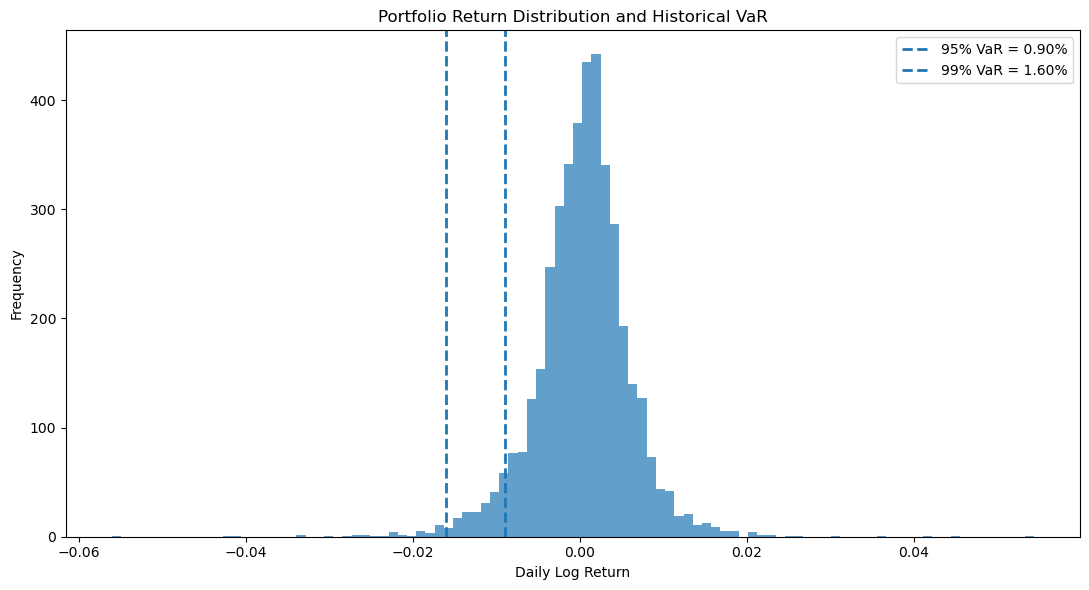

In [16]:
var_95 = historical_risk.loc[
    historical_risk["Confidence Level"] == 0.95,
    "Historical VaR"
].iloc[0]

var_99 = historical_risk.loc[
    historical_risk["Confidence Level"] == 0.99,
    "Historical VaR"
].iloc[0]

fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    portfolio_returns,
    bins=100,
    alpha=0.7
)

ax.axvline(
    -var_95,
    linestyle="--",
    linewidth=2,
    label=f"95% VaR = {var_95:.2%}"
)

ax.axvline(
    -var_99,
    linestyle="--",
    linewidth=2,
    label=f"99% VaR = {var_99:.2%}"
)

ax.set_title("Portfolio Return Distribution and Historical VaR")
ax.set_xlabel("Daily Log Return")
ax.set_ylabel("Frequency")

ax.legend()

plt.tight_layout()
plt.show()

### Interpretation

The historical simulation estimates a one-day 95% VaR of approximately 0.90% and a 99% VaR of approximately 1.60%. For a hypothetical $1 million portfolio, these correspond to losses of approximately $9,000 and $16,000 respectively.

Expected Shortfall is materially larger, reaching approximately 1.39% at the 95% confidence level and 2.27% at 99%. Therefore, when the portfolio breaches its 99% VaR threshold, the average historical loss within that tail is approximately $22,700 per $1 million of exposure.

The increasing gap between VaR and Expected Shortfall highlights the importance of modelling loss severity beyond a single quantile. This is particularly relevant given the portfolio's negative skewness and high excess kurtosis, which indicate that extreme returns occur more frequently than would be expected under a normal distribution.


## 5. Parametric Gaussian VaR and Expected Shortfall

Parametric VaR estimates portfolio risk by assuming that returns follow a specified probability distribution. Under the Gaussian approach, VaR is determined using the portfolio's estimated mean and standard deviation together with the relevant standard-normal quantile.

Unlike historical simulation, this method does not rely directly on empirical tail observations. It is computationally efficient but depends on the assumption that returns are normally distributed.

Given the negative skewness and substantial excess kurtosis observed in the portfolio returns, comparing Gaussian estimates with historical estimates provides a useful test of the normality assumption.


In [17]:
mu = portfolio_returns.mean()
sigma = portfolio_returns.std()

parametric_results = []

for confidence in confidence_levels:
    
    alpha = 1 - confidence
    
    z = stats.norm.ppf(alpha)
    
    var = -(mu + sigma * z)
    
    es = -mu + sigma * (
        stats.norm.pdf(z) / alpha
    )
    
    parametric_results.append({
        "Confidence Level": confidence,
        "Gaussian VaR": var,
        "Gaussian ES": es
    })

parametric_risk = pd.DataFrame(parametric_results)

parametric_risk["VaR ($)"] = (
    parametric_risk["Gaussian VaR"]
    * PORTFOLIO_VALUE
)

parametric_risk["ES ($)"] = (
    parametric_risk["Gaussian ES"]
    * PORTFOLIO_VALUE
)

parametric_risk

,Confidence Level,Gaussian VaR,Gaussian ES,VaR ($),ES ($)
0,0.9500,0.0094,0.0118,"9,354.4730","11,819.2419"
1,0.9900,0.0134,0.0154,"13,374.3102","15,373.1349"


In [18]:
risk_comparison = historical_risk[
    [
        "Confidence Level",
        "Historical VaR",
        "Historical ES"
    ]
].merge(
    parametric_risk[
        [
            "Confidence Level",
            "Gaussian VaR",
            "Gaussian ES"
        ]
    ],
    on="Confidence Level"
)

risk_comparison

,Confidence Level,Historical VaR,Historical ES,Gaussian VaR,Gaussian ES
0,0.9500,0.0090,0.0139,0.0094,0.0118
1,0.9900,0.0160,0.0227,0.0134,0.0154


In [19]:
risk_comparison["VaR Difference"] = (
    risk_comparison["Gaussian VaR"]
    - risk_comparison["Historical VaR"]
)

risk_comparison["ES Difference"] = (
    risk_comparison["Gaussian ES"]
    - risk_comparison["Historical ES"]
)

risk_comparison

,Confidence Level,Historical VaR,Historical ES,Gaussian VaR,Gaussian ES,VaR Difference,ES Difference
0,0.9500,0.0090,0.0139,0.0094,0.0118,0.0004,-0.0021
1,0.9900,0.0160,0.0227,0.0134,0.0154,-0.0027,-0.0073


### Interpretation

The Gaussian model produces a 95% VaR broadly similar to historical simulation, but the difference becomes materially larger deeper in the tail.

At the 99% confidence level, historical VaR is approximately 1.60% compared with 1.34% under the Gaussian assumption. The divergence is even greater for Expected Shortfall: historical ES is approximately 2.27%, while Gaussian ES is only about 1.54%.

This indicates that the normal distribution understates severe tail losses in the portfolio. The result is consistent with the observed negative skewness and high excess kurtosis of portfolio returns, which imply more frequent and more severe extreme observations than predicted by a Gaussian distribution.


## 6. Monte Carlo VaR and Expected Shortfall

Monte Carlo simulation estimates portfolio risk by generating a large number of simulated asset-return scenarios from an assumed joint distribution.

The simulation uses the historical mean vector and covariance matrix of the five asset returns. Correlations between assets are therefore incorporated explicitly before the simulated asset returns are aggregated using the portfolio weights.

This approach provides flexibility for scenario generation, but its accuracy still depends on the assumed return distribution and estimated covariance structure.


In [20]:
mean_vector = returns.mean().values
cov_matrix = returns.cov().values

n_simulations = 100_000

np.random.seed(42)

simulated_asset_returns = np.random.multivariate_normal(
    mean=mean_vector,
    cov=cov_matrix,
    size=n_simulations
)

simulated_portfolio_returns = (
    simulated_asset_returns @ weights.to_numpy()
)

print(f"Simulations: {n_simulations:,}")
print(f"Mean simulated return: {simulated_portfolio_returns.mean():.4%}")
print(f"Simulated volatility: {simulated_portfolio_returns.std():.4%}")


Simulations: 100,000
Mean simulated return: 0.0376%
Simulated volatility: 0.5910%


In [21]:
mc_results = []

for confidence in confidence_levels:

    alpha = 1 - confidence

    var = -np.quantile(
        simulated_portfolio_returns,
        alpha
    )

    tail_returns = simulated_portfolio_returns[
        simulated_portfolio_returns <= -var
    ]

    es = -tail_returns.mean()

    mc_results.append({
        "Confidence Level": confidence,
        "Monte Carlo VaR": var,
        "Monte Carlo ES": es
    })

mc_risk = pd.DataFrame(mc_results)

mc_risk["VaR ($)"] = (
    mc_risk["Monte Carlo VaR"]
    * PORTFOLIO_VALUE
)

mc_risk["ES ($)"] = (
    mc_risk["Monte Carlo ES"]
    * PORTFOLIO_VALUE
)

mc_risk

,Confidence Level,Monte Carlo VaR,Monte Carlo ES,VaR ($),ES ($)
0,0.9500,0.0094,0.0118,"9,356.5993","11,844.7973"
1,0.9900,0.0134,0.0154,"13,409.2883","15,440.6551"


In [22]:
full_risk_comparison = (
    risk_comparison
    .merge(
        mc_risk[
            [
                "Confidence Level",
                "Monte Carlo VaR",
                "Monte Carlo ES"
            ]
        ],
        on="Confidence Level"
    )
)

full_risk_comparison

,Confidence Level,Historical VaR,Historical ES,Gaussian VaR,Gaussian ES,VaR Difference,ES Difference,Monte Carlo VaR,Monte Carlo ES
0,0.9500,0.0090,0.0139,0.0094,0.0118,0.0004,-0.0021,0.0094,0.0118
1,0.9900,0.0160,0.0227,0.0134,0.0154,-0.0027,-0.0073,0.0134,0.0154


### Interpretation

The Gaussian Monte Carlo estimates are almost identical to the analytical Gaussian estimates. This is expected because the simulation draws asset returns from a multivariate normal distribution using the historical mean vector and covariance matrix.

The Monte Carlo framework therefore captures the portfolio's cross-asset covariance structure and provides a flexible simulation engine, but it does not resolve the tail-risk limitation of the Gaussian distribution.

At the 99% confidence level, both Gaussian approaches estimate VaR of approximately 1.34% and Expected Shortfall of approximately 1.54%, materially below the historical estimates of approximately 1.60% and 2.27%.

This demonstrates that simulation alone does not guarantee realistic tail-risk estimates: the distributional assumptions used to generate scenarios remain critical.


## 7. VaR Backtesting

VaR backtesting evaluates whether predicted loss thresholds are consistent with subsequently realised portfolio returns.

To avoid look-ahead bias, VaR is estimated using a rolling historical window. For each trading day, the model uses only returns observed before that day to estimate the one-day-ahead VaR threshold.

A 500-trading-day estimation window is used, corresponding to approximately two years of market observations. Backtesting focuses initially on the 99% confidence level, for which a correctly calibrated model should produce VaR exceptions on approximately 1% of trading days.

An exception occurs when the realised portfolio loss exceeds the VaR estimate.


In [23]:
window = 500
confidence = 0.99
alpha = 1 - confidence

rolling_historical_var = (
    portfolio_returns
    .rolling(window=window)
    .quantile(alpha)
    .shift(1)
)

rolling_historical_var = -rolling_historical_var

In [24]:
rolling_mean = (
    portfolio_returns
    .rolling(window=window)
    .mean()
    .shift(1)
)

rolling_std = (
    portfolio_returns
    .rolling(window=window)
    .std()
    .shift(1)
)

z_99 = stats.norm.ppf(alpha)

rolling_gaussian_var = -(
    rolling_mean
    + z_99 * rolling_std
)

In [25]:
backtest = pd.DataFrame({
    "return": portfolio_returns,
    "historical_var": rolling_historical_var,
    "gaussian_var": rolling_gaussian_var
}).dropna()

backtest["historical_exception"] = (
    backtest["return"]
    < -backtest["historical_var"]
)

backtest["gaussian_exception"] = (
    backtest["return"]
    < -backtest["gaussian_var"]
)

backtest.head()

,return,historical_var,gaussian_var,historical_exception,gaussian_exception
Date,,,,,
2011-12-28,-0.0060,0.0129,0.0118,False,False
2011-12-29,0.0028,0.0129,0.0118,False,False
2011-12-30,0.0021,0.0129,0.0118,False,False
2012-01-03,0.0089,0.0129,0.0118,False,False
2012-01-04,-0.0001,0.0129,0.0118,False,False


In [26]:
n_obs = len(backtest)

historical_exceptions = (
    backtest["historical_exception"].sum()
)

gaussian_exceptions = (
    backtest["gaussian_exception"].sum()
)

backtest_summary = pd.DataFrame({
    "Model": [
        "Historical VaR",
        "Gaussian VaR"
    ],
    "Observations": [
        n_obs,
        n_obs
    ],
    "Exceptions": [
        historical_exceptions,
        gaussian_exceptions
    ],
    "Exception Rate": [
        historical_exceptions / n_obs,
        gaussian_exceptions / n_obs
    ],
    "Expected Rate": [
        alpha,
        alpha
    ]
})

backtest_summary

,Model,Observations,Exceptions,Exception Rate,Expected Rate
0,Historical VaR,3668,41,0.0112,0.0100
1,Gaussian VaR,3668,62,0.0169,0.0100


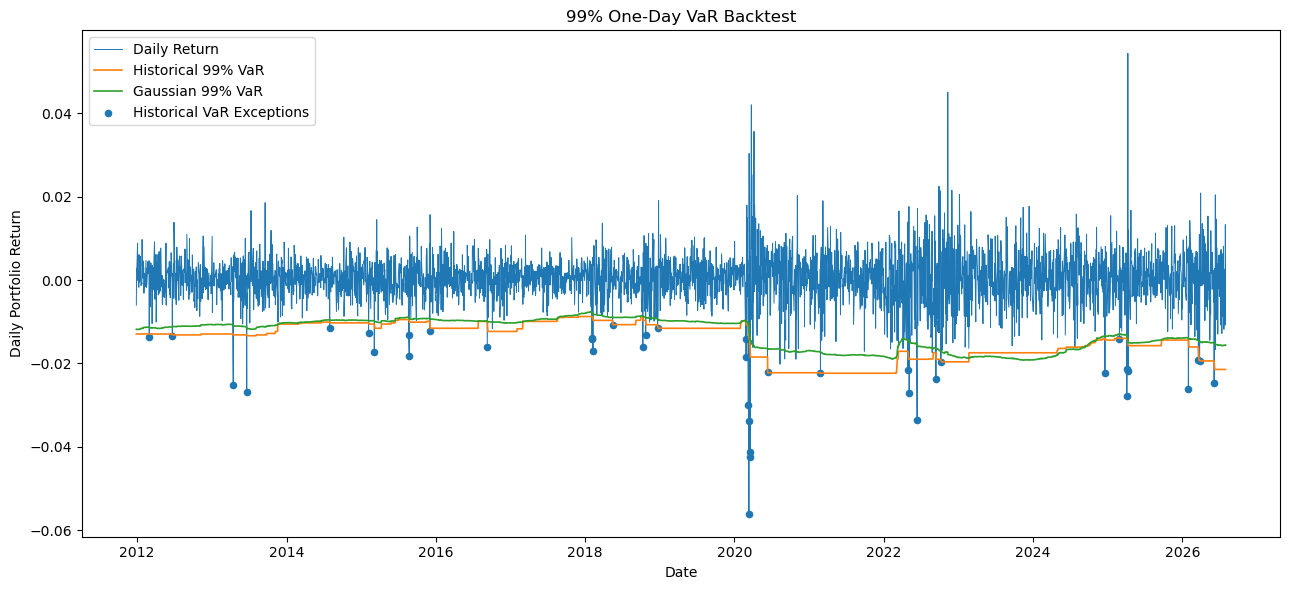

In [27]:
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    backtest.index,
    backtest["return"],
    linewidth=0.7,
    label="Daily Return"
)

ax.plot(
    backtest.index,
    -backtest["historical_var"],
    linewidth=1.2,
    label="Historical 99% VaR"
)

ax.plot(
    backtest.index,
    -backtest["gaussian_var"],
    linewidth=1.2,
    label="Gaussian 99% VaR"
)

exceptions = backtest[
    backtest["historical_exception"]
]

ax.scatter(
    exceptions.index,
    exceptions["return"],
    s=20,
    label="Historical VaR Exceptions"
)

ax.set_title("99% One-Day VaR Backtest")
ax.set_ylabel("Daily Portfolio Return")
ax.set_xlabel("Date")

ax.legend()

plt.tight_layout()
plt.show()

## 8. Statistical VaR Backtesting

Exception rates alone do not establish whether a VaR model is adequately calibrated. Formal statistical backtesting is therefore used to assess whether observed VaR breaches are consistent with the expected frequency.

### Kupiec Proportion-of-Failures Test

The Kupiec test evaluates unconditional coverage by comparing the observed exception frequency with the theoretical exception probability implied by the VaR confidence level.

For a 99% VaR model, the expected exception probability is 1%.

The null hypothesis is that the model has the correct unconditional exception probability. A p-value below 5% provides evidence against correct unconditional coverage.


In [28]:
def kupiec_test(exceptions, n_obs, expected_rate):
    
    x = exceptions
    n = n_obs
    p = expected_rate
    
    observed_rate = x / n

    if x == 0 or x == n:
        return np.nan, np.nan

    log_likelihood_null = (
        (n - x) * np.log(1 - p)
        + x * np.log(p)
    )

    log_likelihood_alt = (
        (n - x) * np.log(1 - observed_rate)
        + x * np.log(observed_rate)
    )

    lr_stat = -2 * (
        log_likelihood_null
        - log_likelihood_alt
    )

    p_value = 1 - stats.chi2.cdf(
        lr_stat,
        df=1
    )

    return lr_stat, p_value

In [29]:
kupiec_results = []

for model, exceptions in [
    ("Historical VaR", historical_exceptions),
    ("Gaussian VaR", gaussian_exceptions)
]:

    lr_stat, p_value = kupiec_test(
        exceptions=exceptions,
        n_obs=n_obs,
        expected_rate=alpha
    )

    kupiec_results.append({
        "Model": model,
        "Exceptions": exceptions,
        "Exception Rate": exceptions / n_obs,
        "Kupiec LR": lr_stat,
        "p-value": p_value,
        "Reject at 5%": p_value < 0.05
    })

kupiec_results = pd.DataFrame(kupiec_results)

kupiec_results

,Model,Exceptions,Exception Rate,Kupiec LR,p-value,Reject at 5%
0,Historical VaR,41,0.0112,0.4951,0.4817,False
1,Gaussian VaR,62,0.0169,14.6249,0.0001,True


In [30]:
exceptions_by_year = pd.DataFrame({
    "Historical VaR": (
        backtest["historical_exception"]
        .groupby(backtest.index.year)
        .sum()
    ),
    "Gaussian VaR": (
        backtest["gaussian_exception"]
        .groupby(backtest.index.year)
        .sum()
    )
})

exceptions_by_year

,Historical VaR,Gaussian VaR
Date,,
2011,0,0
2012,2,2
2013,2,3
2014,1,1
2015,5,7
2016,1,2
2017,0,0
2018,7,12
2019,0,0


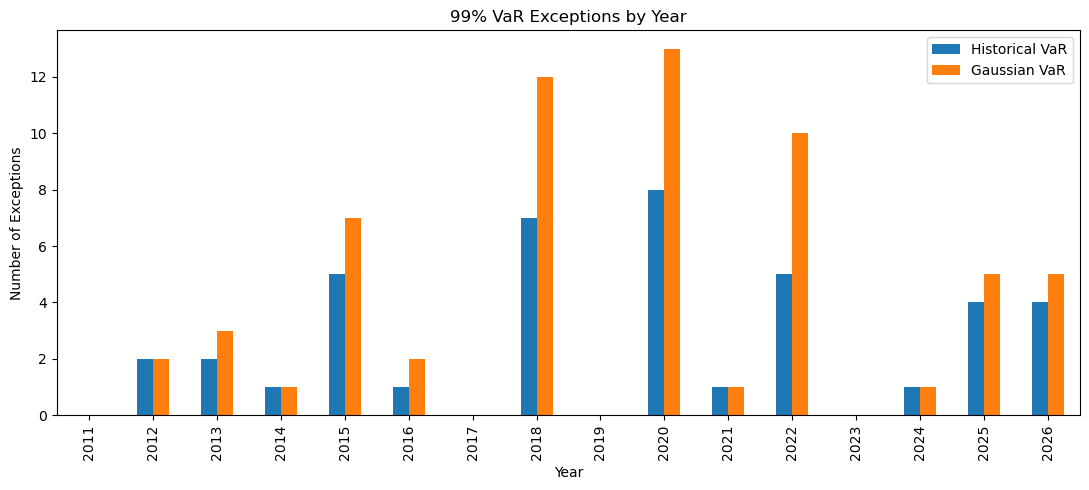

In [31]:
fig, ax = plt.subplots(figsize=(11, 5))

exceptions_by_year.plot(
    kind="bar",
    ax=ax
)

ax.set_title("99% VaR Exceptions by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Exceptions")

plt.tight_layout()
plt.show()

### Kupiec Test Results

The historical VaR model records 41 exceptions across 3,668 backtesting observations, corresponding to an exception rate of approximately 1.12%. The Kupiec test produces a p-value of approximately 0.48, so the null hypothesis of correct unconditional coverage is not rejected at the 5% significance level.

The Gaussian VaR model records 62 exceptions, corresponding to an exception rate of approximately 1.69%. Its Kupiec p-value is approximately 0.0001, leading to rejection of the null hypothesis of correct unconditional coverage.

The results therefore provide statistical evidence that the rolling Gaussian model underestimates one-day tail risk, while the historical model achieves substantially better unconditional coverage.


## 9. Exception Independence and Conditional Coverage

Correct exception frequency is only one requirement of an effective VaR model. VaR exceptions should also be approximately independent through time.

A model may achieve the correct overall number of exceptions while experiencing clusters of breaches during periods of market stress. Such clustering suggests that the model is slow to adapt to changes in the underlying risk environment.

The Christoffersen independence test evaluates whether the probability of a VaR exception depends on whether an exception occurred on the preceding trading day.

The conditional coverage test combines the Kupiec unconditional-coverage test with the Christoffersen independence test. A model therefore achieves satisfactory conditional coverage only when both the frequency and temporal behaviour of exceptions are consistent with the VaR specification.


In [32]:
def christoffersen_independence_test(exception_series):

    hits = exception_series.astype(int).values

    previous = hits[:-1]
    current = hits[1:]

    n00 = np.sum((previous == 0) & (current == 0))
    n01 = np.sum((previous == 0) & (current == 1))
    n10 = np.sum((previous == 1) & (current == 0))
    n11 = np.sum((previous == 1) & (current == 1))

    pi01 = n01 / (n00 + n01)
    pi11 = n11 / (n10 + n11)

    pi = (n01 + n11) / (
        n00 + n01 + n10 + n11
    )

    log_likelihood_independent = (
        (n00 + n10) * np.log(1 - pi)
        + (n01 + n11) * np.log(pi)
    )

    log_likelihood_markov = (
        n00 * np.log(1 - pi01)
        + n01 * np.log(pi01)
        + n10 * np.log(1 - pi11)
        + n11 * np.log(pi11)
    )

    lr_ind = -2 * (
        log_likelihood_independent
        - log_likelihood_markov
    )

    p_value = 1 - stats.chi2.cdf(
        lr_ind,
        df=1
    )

    return {
        "n00": n00,
        "n01": n01,
        "n10": n10,
        "n11": n11,
        "LR Independence": lr_ind,
        "Independence p-value": p_value
    }

In [33]:
independence_results = []

for model, column in [
    ("Historical VaR", "historical_exception"),
    ("Gaussian VaR", "gaussian_exception")
]:

    result = christoffersen_independence_test(
        backtest[column]
    )

    result["Model"] = model

    independence_results.append(result)

independence_results = pd.DataFrame(
    independence_results
)

independence_results[
    [
        "Model",
        "n00",
        "n01",
        "n10",
        "n11",
        "LR Independence",
        "Independence p-value"
    ]
]

,Model,n00,n01,n10,n11,LR Independence,Independence p-value
0,Historical VaR,3589,37,37,4,10.8882,0.0010
1,Gaussian VaR,3551,54,54,8,20.2767,0.0000


In [34]:
conditional_results = []

for model in [
    "Historical VaR",
    "Gaussian VaR"
]:

    kupiec_lr = kupiec_results.loc[
        kupiec_results["Model"] == model,
        "Kupiec LR"
    ].iloc[0]

    ind_lr = independence_results.loc[
        independence_results["Model"] == model,
        "LR Independence"
    ].iloc[0]

    lr_cc = kupiec_lr + ind_lr

    p_value_cc = 1 - stats.chi2.cdf(
        lr_cc,
        df=2
    )

    conditional_results.append({
        "Model": model,
        "Kupiec LR": kupiec_lr,
        "Independence LR": ind_lr,
        "Conditional Coverage LR": lr_cc,
        "Conditional Coverage p-value": p_value_cc,
        "Reject at 5%": p_value_cc < 0.05
    })

conditional_coverage = pd.DataFrame(
    conditional_results
)

conditional_coverage

,Model,Kupiec LR,Independence LR,Conditional Coverage LR,Conditional Coverage p-value,Reject at 5%
0,Historical VaR,0.4951,10.8882,11.3832,0.0034,True
1,Gaussian VaR,14.6249,20.2767,34.9016,0.0000,True


In [35]:
clustering_summary = []

for model, column in [
    ("Historical VaR", "historical_exception"),
    ("Gaussian VaR", "gaussian_exception")
]:

    hits = backtest[column].astype(int).values

    previous = hits[:-1]
    current = hits[1:]

    p_exception_after_no_exception = (
        current[previous == 0].mean()
    )

    p_exception_after_exception = (
        current[previous == 1].mean()
    )

    clustering_summary.append({
        "Model": model,
        "P(Exception | No Prior Exception)": 
            p_exception_after_no_exception,
        "P(Exception | Prior Exception)": 
            p_exception_after_exception
    })

clustering_summary = pd.DataFrame(
    clustering_summary
)

clustering_summary

,Model,P(Exception | No Prior Exception),P(Exception | Prior Exception)
0,Historical VaR,0.0102,0.0976
1,Gaussian VaR,0.0150,0.1290


### Conditional Coverage Results

The Christoffersen results reveal an important limitation that is not captured by unconditional exception frequencies alone.

Although Historical VaR passes the Kupiec unconditional-coverage test, it fails the independence test with a p-value of approximately 0.001. Its exceptions are therefore significantly clustered through time. The probability of an exception following a non-exception day is approximately 1.02%, whereas the probability following another exception rises to approximately 9.76%.

Consequently, Historical VaR also fails the combined conditional-coverage test at the 5% significance level. This indicates that while its long-run exception frequency is reasonably calibrated, the model does not adapt sufficiently quickly to periods of elevated market risk.

Gaussian VaR performs more poorly. It fails both unconditional coverage and exception independence, with the probability of an exception increasing from approximately 1.50% following a non-exception day to 12.90% following an exception.

These results suggest that volatility is time-varying and persistent. A risk model based on a relatively slow-moving rolling estimation window can therefore underestimate risk when markets transition rapidly into high-volatility regimes.


## 10. EWMA Volatility VaR

The backtesting results indicate that portfolio volatility is time-varying and that VaR exceptions tend to cluster during stressed market regimes.

To improve responsiveness to changing volatility, an Exponentially Weighted Moving Average (EWMA) model is introduced. Unlike an equally weighted rolling volatility estimator, EWMA assigns progressively greater importance to recent observations.

The conditional variance evolves according to:

$$
\sigma_t^2
=
\lambda\sigma_{t-1}^2
+
(1-\lambda)r_{t-1}^2
$$

where $\lambda$ controls the persistence of volatility. A value of 0.94 is used for daily returns.

The resulting volatility estimate is used to construct a one-day 99% Gaussian VaR forecast and evaluated using the same backtesting framework.

For one-day risk forecasting, the conditional mean return is assumed to be zero, a common simplifying assumption because daily expected returns are small relative to daily volatility.


In [36]:
lambda_ewma = 0.94

returns_array = portfolio_returns.values

ewma_variance = np.zeros(len(returns_array))

# Initialise using the first 500 observations
ewma_variance[window] = (
    portfolio_returns.iloc[:window].var()
)

for t in range(window + 1, len(returns_array)):
    
    ewma_variance[t] = (
        lambda_ewma * ewma_variance[t - 1]
        + (1 - lambda_ewma)
        * returns_array[t - 1] ** 2
    )

ewma_volatility = pd.Series(
    np.sqrt(ewma_variance),
    index=portfolio_returns.index
)

ewma_volatility.iloc[:window] = np.nan

In [37]:
ewma_var = -(
    z_99 * ewma_volatility
)

backtest["ewma_var"] = (
    ewma_var.reindex(backtest.index)
)

backtest["ewma_exception"] = (
    backtest["return"]
    < -backtest["ewma_var"]
)

ewma_exceptions = (
    backtest["ewma_exception"].sum()
)

print("EWMA VaR exceptions:", ewma_exceptions)

print(
    "EWMA exception rate:",
    ewma_exceptions / len(backtest)
)

EWMA VaR exceptions: 76
EWMA exception rate: 0.020719738276990186


In [38]:
model_comparison = pd.DataFrame({
    "Model": [
        "Historical VaR",
        "Gaussian VaR",
        "EWMA VaR"
    ],
    "Exceptions": [
        historical_exceptions,
        gaussian_exceptions,
        ewma_exceptions
    ],
    "Exception Rate": [
        historical_exceptions / n_obs,
        gaussian_exceptions / n_obs,
        ewma_exceptions / n_obs
    ],
    "Expected Rate": [
        alpha,
        alpha,
        alpha
    ]
})

model_comparison

,Model,Exceptions,Exception Rate,Expected Rate
0,Historical VaR,41,0.0112,0.0100
1,Gaussian VaR,62,0.0169,0.0100
2,EWMA VaR,76,0.0207,0.0100


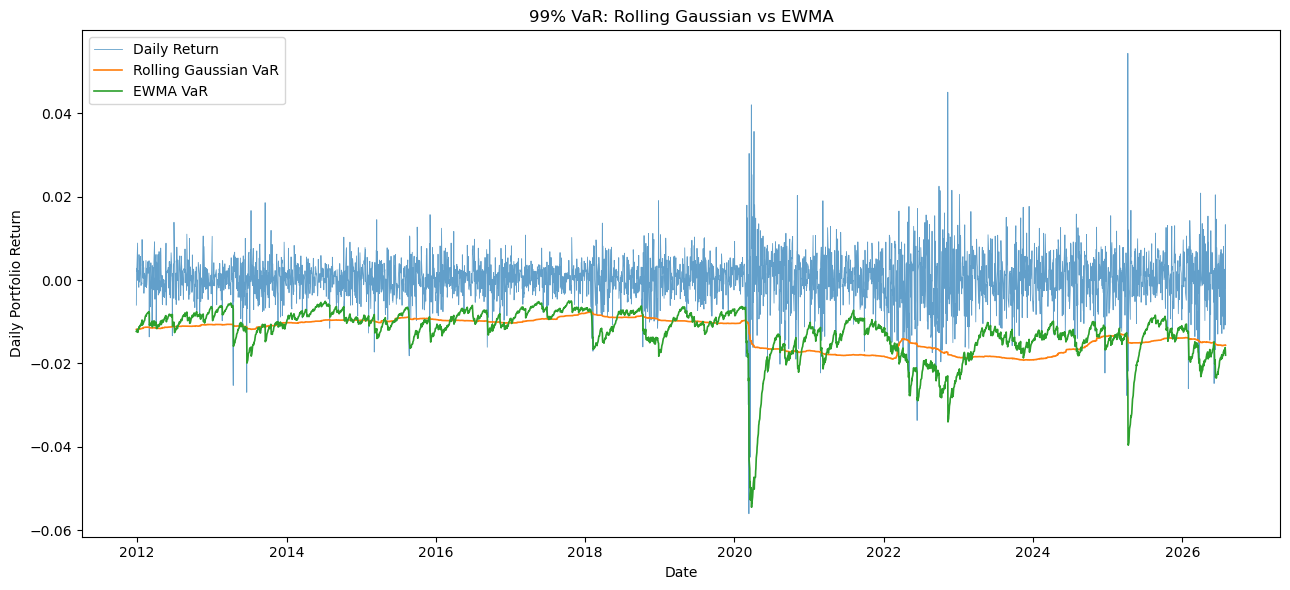

In [39]:
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    backtest.index,
    backtest["return"],
    linewidth=0.6,
    alpha=0.7,
    label="Daily Return"
)

ax.plot(
    backtest.index,
    -backtest["gaussian_var"],
    linewidth=1.2,
    label="Rolling Gaussian VaR"
)

ax.plot(
    backtest.index,
    -backtest["ewma_var"],
    linewidth=1.2,
    label="EWMA VaR"
)

ax.set_title(
    "99% VaR: Rolling Gaussian vs EWMA"
)

ax.set_ylabel("Daily Portfolio Return")
ax.set_xlabel("Date")

ax.legend()

plt.tight_layout()
plt.show()

In [40]:
ewma_kupiec_lr, ewma_kupiec_p = kupiec_test(
    exceptions=ewma_exceptions,
    n_obs=n_obs,
    expected_rate=alpha
)

ewma_ind = christoffersen_independence_test(
    backtest["ewma_exception"]
)

ewma_cc_lr = (
    ewma_kupiec_lr
    + ewma_ind["LR Independence"]
)

ewma_cc_p = 1 - stats.chi2.cdf(
    ewma_cc_lr,
    df=2
)

ewma_test_results = pd.DataFrame({
    "Test": [
        "Kupiec Unconditional Coverage",
        "Christoffersen Independence",
        "Conditional Coverage"
    ],
    "LR Statistic": [
        ewma_kupiec_lr,
        ewma_ind["LR Independence"],
        ewma_cc_lr
    ],
    "p-value": [
        ewma_kupiec_p,
        ewma_ind["Independence p-value"],
        ewma_cc_p
    ]
})

ewma_test_results["Reject at 5%"] = (
    ewma_test_results["p-value"] < 0.05
)

ewma_test_results

,Test,LR Statistic,p-value,Reject at 5%
0,Kupiec Unconditional Coverage,32.5196,0.0000,True
1,Christoffersen Independence,10.8514,0.0010,True
2,Conditional Coverage,43.3710,0.0000,True


In [41]:
hits = backtest["ewma_exception"].astype(int).values

previous = hits[:-1]
current = hits[1:]

ewma_p_no_exception = (
    current[previous == 0].mean()
)

ewma_p_after_exception = (
    current[previous == 1].mean()
)

print(
    "P(Exception | No Prior Exception):",
    ewma_p_no_exception
)

print(
    "P(Exception | Prior Exception):",
    ewma_p_after_exception
)

P(Exception | No Prior Exception): 0.01921470342522974
P(Exception | Prior Exception): 0.09210526315789473


### EWMA Backtesting Results

The EWMA specification responds considerably faster to changes in market volatility than the 500-day rolling Gaussian model. However, greater volatility responsiveness does not translate into improved VaR coverage.

The EWMA model produces an exception rate of approximately 2.07%, more than twice the theoretical 1% rate for a 99% VaR model. The Kupiec test therefore strongly rejects correct unconditional coverage.

Exception independence is also rejected. The probability of an exception following a non-exception day is approximately 1.92%, but rises to approximately 9.21% immediately following another exception. The combined conditional-coverage test is consequently rejected.

These results indicate that modelling time-varying volatility alone is insufficient. Although EWMA adapts more rapidly to changing volatility regimes, its Gaussian innovation assumption remains unable to represent the heavy tails observed in portfolio returns adequately.


## 11. Residual Tail Diagnostics

The Gaussian EWMA model improves responsiveness to changing volatility but continues to underestimate tail risk. This suggests that volatility dynamics alone do not explain the observed VaR failures.

To diagnose the remaining distributional problem, portfolio returns are standardized by EWMA conditional volatility and the residual distribution is examined. If the residuals remain heavy-tailed after volatility adjustment, a Student-t innovation distribution is more appropriate than a Gaussian specification.

This section is diagnostic only. Formal Student-t VaR backtesting is performed subsequently using rolling parameters estimated only from information available before each forecast date.


In [42]:
valid_ewma = ewma_volatility.dropna()

standardized_residuals = (
    portfolio_returns.reindex(valid_ewma.index)
    / valid_ewma
).dropna()

print(
    standardized_residuals.describe()
)

print(
    "Residual excess kurtosis:",
    stats.kurtosis(
        standardized_residuals,
        fisher=True
    )
)

count   3,668.0000
mean        0.0679
std         1.0541
min        -8.5191
25%        -0.5198
50%         0.1302
75%         0.7161
max         5.2676
dtype: float64
Residual excess kurtosis: 2.9793277192020344


In [43]:
t_df, t_loc, t_scale = stats.t.fit(
    standardized_residuals.values,
    floc=0
)

print(f"Estimated degrees of freedom: {t_df:.2f}")
print(f"Estimated scale: {t_scale:.4f}")

Estimated degrees of freedom: 6.13
Estimated scale: 0.8645


In [44]:
fitted_t_quantile = stats.t.ppf(
    alpha,
    df=t_df,
    loc=0,
    scale=t_scale
)

print(f"Gaussian 1% quantile: {z_99:.4f}")
print(
    f"Fitted Student-t 1% residual quantile: "
    f"{fitted_t_quantile:.4f}"
)


Gaussian 1% quantile: -2.3263
Standardized Student-t 1% quantile: -2.5615


## 12. Rolling Student-t EWMA Backtest

The previous Student-t analysis estimated the degrees-of-freedom parameter using the full standardized-residual sample. That is useful diagnostically but introduces look-ahead bias if used for historical backtesting.

A stricter one-day-ahead implementation therefore re-estimates the Student-t tail parameter using only information available before each forecast date.

The EWMA volatility forecast continues to use only lagged returns. Student-t degrees of freedom are estimated from a rolling history of standardized residuals, ensuring that future observations do not influence past VaR forecasts.


In [45]:
student_t_window = 500

rolling_student_t_var = pd.Series(
    index=portfolio_returns.index,
    dtype=float
)

rolling_student_t_df = pd.Series(
    index=portfolio_returns.index,
    dtype=float
)

rolling_student_t_scale = pd.Series(
    index=portfolio_returns.index,
    dtype=float
)

for t in range(
    window + student_t_window,
    len(portfolio_returns)
):

    # EWMA volatility forecast for date t.
    # This only contains information through t-1.
    sigma_t = ewma_volatility.iloc[t]

    # Use only residuals available before forecast date t
    residual_window = (
        portfolio_returns.iloc[
            t - student_t_window:t
        ]
        / ewma_volatility.iloc[
            t - student_t_window:t
        ]
    ).dropna()

    if len(residual_window) < 100:
        continue

    # Fit Student-t to historical standardized residuals
    df_t, _, scale_t = stats.t.fit(
        residual_window.values,
        floc=0
    )

    if df_t <= 2:
        continue

    # Lower-tail Student-t quantile using fitted scale
    q_t = stats.t.ppf(
        alpha,
        df=df_t,
        loc=0,
        scale=scale_t
    )

    rolling_student_t_df.iloc[t] = df_t
    rolling_student_t_scale.iloc[t] = scale_t

    rolling_student_t_var.iloc[t] = -(
        q_t * sigma_t
    )

In [46]:
backtest["rolling_student_t_var"] = (
    rolling_student_t_var
    .reindex(backtest.index)
)

backtest["rolling_student_t_exception"] = (
    backtest["return"]
    < -backtest["rolling_student_t_var"]
)

student_t_strict = (
    backtest[
        backtest["rolling_student_t_var"]
        .notna()
    ]
    .copy()
)

student_t_strict_exceptions = (
    student_t_strict[
        "rolling_student_t_exception"
    ]
    .sum()
)

student_t_strict_n = len(
    student_t_strict
)

student_t_strict_rate = (
    student_t_strict_exceptions
    / student_t_strict_n
)

print(
    "Observations:",
    student_t_strict_n
)

print(
    "Exceptions:",
    student_t_strict_exceptions
)

print(
    "Exception rate:",
    student_t_strict_rate
)

Observations: 3168
Exceptions: 45
Exception rate: 0.014204545454545454


In [47]:
rolling_df_valid = (
    rolling_student_t_df
    .dropna()
)

print(
    rolling_df_valid.describe()
)

count   3,168.0000
mean        7.4607
std         2.8279
min         3.8641
25%         5.3744
50%         6.5672
75%         9.2402
max        17.5018
dtype: float64


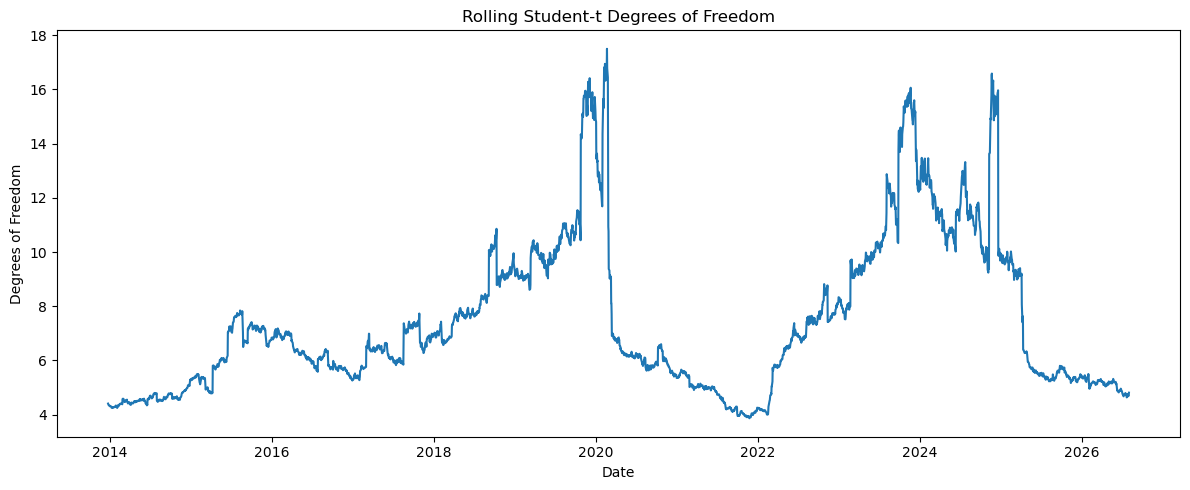

In [48]:
fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    rolling_df_valid.index,
    rolling_df_valid
)

ax.set_title(
    "Rolling Student-t Degrees of Freedom"
)

ax.set_ylabel(
    "Degrees of Freedom"
)

ax.set_xlabel(
    "Date"
)

plt.tight_layout()
plt.show()

In [49]:
strict_kupiec_lr, strict_kupiec_p = kupiec_test(
    exceptions=student_t_strict_exceptions,
    n_obs=student_t_strict_n,
    expected_rate=alpha
)

In [50]:
strict_ind = (
    christoffersen_independence_test(
        student_t_strict[
            "rolling_student_t_exception"
        ]
    )
)

In [51]:
strict_cc_lr = (
    strict_kupiec_lr
    + strict_ind[
        "LR Independence"
    ]
)

strict_cc_p = (
    1
    - stats.chi2.cdf(
        strict_cc_lr,
        df=2
    )
)

strict_student_t_results = pd.DataFrame({
    "Test": [
        "Kupiec Unconditional Coverage",
        "Christoffersen Independence",
        "Conditional Coverage"
    ],
    "LR Statistic": [
        strict_kupiec_lr,
        strict_ind[
            "LR Independence"
        ],
        strict_cc_lr
    ],
    "p-value": [
        strict_kupiec_p,
        strict_ind[
            "Independence p-value"
        ],
        strict_cc_p
    ]
})

strict_student_t_results[
    "Reject at 5%"
] = (
    strict_student_t_results[
        "p-value"
    ] < 0.05
)

strict_student_t_results

,Test,LR Statistic,p-value,Reject at 5%
0,Kupiec Unconditional Coverage,5.0046,0.0253,True
1,Christoffersen Independence,12.7384,0.0004,True
2,Conditional Coverage,17.7429,0.0001,True


In [52]:
hits = (
    student_t_strict[
        "rolling_student_t_exception"
    ]
    .astype(int)
    .values
)

previous = hits[:-1]
current = hits[1:]

strict_p_no_exception = (
    current[
        previous == 0
    ].mean()
)

strict_p_after_exception = (
    current[
        previous == 1
    ].mean()
)

print(
    "P(Exception | No Prior Exception):",
    strict_p_no_exception
)

print(
    "P(Exception | Prior Exception):",
    strict_p_after_exception
)

P(Exception | No Prior Exception): 0.012812299807815503
P(Exception | Prior Exception): 0.1111111111111111


### Rolling Student-t Backtest Results

Removing look-ahead bias improves the methodological validity of the Student-t EWMA backtest. The rolling specification produces 45 exceptions across 3,168 one-day-ahead forecasts, corresponding to an exception rate of approximately 1.42%.

This is closer to the theoretical 1% target than the earlier full-sample Student-t specification, but the Kupiec test still rejects correct unconditional coverage at the 5% level.

Exception independence is also rejected. The probability of an exception following a non-exception day is approximately 1.28%, but rises to approximately 11.11% following another exception. The model consequently fails the combined conditional-coverage test.

The rolling Student-t degrees of freedom vary materially through time, with lower values indicating heavier estimated tails during stressed market regimes. This demonstrates that tail behaviour itself is time-varying, but even a dynamically estimated heavy-tailed model does not fully eliminate clustered extreme losses.


## 13. Final VaR Model Comparison

The preceding analysis evaluates multiple approaches to one-day 99% Value at Risk, ranging from non-parametric historical simulation to volatility-responsive parametric models.

The final comparison focuses on both empirical exception frequency and formal backtesting performance. Particular attention is given to the distinction between unconditional coverage and exception independence.

The rolling Student-t EWMA specification is treated as the final Student-t backtest because its parameters are estimated using only information available prior to each forecast date, avoiding look-ahead bias.


In [53]:
final_var_comparison = pd.DataFrame({
    "Model": [
        "Historical VaR",
        "Rolling Gaussian VaR",
        "EWMA Gaussian VaR",
        "Rolling Student-t EWMA VaR"
    ],
    "Observations": [
        n_obs,
        n_obs,
        n_obs,
        student_t_strict_n
    ],
    "Exceptions": [
        historical_exceptions,
        gaussian_exceptions,
        ewma_exceptions,
        student_t_strict_exceptions
    ],
    "Exception Rate": [
        historical_exceptions / n_obs,
        gaussian_exceptions / n_obs,
        ewma_exceptions / n_obs,
        student_t_strict_rate
    ],
    "Kupiec p-value": [
        kupiec_results.loc[
            kupiec_results["Model"] == "Historical VaR",
            "p-value"
        ].iloc[0],
        kupiec_results.loc[
            kupiec_results["Model"] == "Gaussian VaR",
            "p-value"
        ].iloc[0],
        ewma_kupiec_p,
        strict_kupiec_p
    ],
    "Independence p-value": [
        independence_results.loc[
            independence_results["Model"] == "Historical VaR",
            "Independence p-value"
        ].iloc[0],
        independence_results.loc[
            independence_results["Model"] == "Gaussian VaR",
            "Independence p-value"
        ].iloc[0],
        ewma_ind["Independence p-value"],
        strict_ind["Independence p-value"]
    ],
    "Conditional Coverage p-value": [
        conditional_coverage.loc[
            conditional_coverage["Model"] == "Historical VaR",
            "Conditional Coverage p-value"
        ].iloc[0],
        conditional_coverage.loc[
            conditional_coverage["Model"] == "Gaussian VaR",
            "Conditional Coverage p-value"
        ].iloc[0],
        ewma_cc_p,
        strict_cc_p
    ]
})

final_var_comparison["Kupiec Pass"] = (
    final_var_comparison["Kupiec p-value"] >= 0.05
)

final_var_comparison["Independence Pass"] = (
    final_var_comparison["Independence p-value"] >= 0.05
)

final_var_comparison["Conditional Coverage Pass"] = (
    final_var_comparison[
        "Conditional Coverage p-value"
    ] >= 0.05
)

final_var_comparison

,Model,Observations,Exceptions,Exception Rate,Kupiec p-value,Independence p-value,Conditional Coverage p-value,Kupiec Pass,Independence Pass,Conditional Coverage Pass
0,Historical VaR,3668,41,0.0112,0.4817,0.0010,0.0034,True,False,False
1,Rolling Gaussian VaR,3668,62,0.0169,0.0001,0.0000,0.0000,False,False,False
2,EWMA Gaussian VaR,3668,76,0.0207,0.0000,0.0010,0.0000,False,False,False
3,Rolling Student-t EWMA VaR,3168,45,0.0142,0.0253,0.0004,0.0001,False,False,False


### Model Comparison Interpretation

Historical VaR provides the strongest unconditional calibration, with an exception rate closest to the theoretical 1% target and no rejection under the Kupiec test. However, it fails the independence and conditional-coverage tests because losses exceeding VaR remain clustered through time.

The Gaussian specifications perform less effectively. Rolling Gaussian VaR underestimates tail risk, while introducing EWMA volatility improves responsiveness but results in even more frequent exceptions. This demonstrates that greater volatility responsiveness does not necessarily imply better tail calibration when the conditional return distribution remains Gaussian.

The rolling Student-t EWMA model addresses both time-varying volatility and heavy-tailed innovations while avoiding look-ahead bias. It improves substantially on Gaussian EWMA, but its exception rate remains above the theoretical target and clustered exceptions persist.

No model therefore satisfies all statistical backtesting criteria. Historical VaR provides the strongest unconditional coverage, while the Student-t EWMA analysis demonstrates the value—and limitations—of explicitly modelling dynamic volatility and heavy-tailed returns.


## 14. Portfolio Stress Testing

VaR and Expected Shortfall estimate tail risk using the statistical properties of historical returns. They do not, however, describe portfolio behaviour under specific market crises or deliberately constructed adverse scenarios.

Stress testing complements VaR by evaluating portfolio losses under severe but economically interpretable market conditions.

Two approaches are considered:

1. **Historical stress testing** — applying asset returns observed during major periods of market disruption.
2. **Hypothetical stress testing** — imposing predefined shocks on individual portfolio components.

Historical scenarios are evaluated first.


In [ ]:
historical_scenarios = {
    "2018 Q4 Selloff": (
        "2018-10-01",
        "2018-12-24"
    ),
    "COVID-19 Crash": (
        "2020-02-19",
        "2020-03-23"
    ),
    "2022 Market Selloff": (
        "2022-01-03",
        "2022-10-20"
    )
}


In [ ]:
historical_stress_results = []

for scenario, (start, end) in historical_scenarios.items():

    scenario_log_returns = returns.loc[start:end]

    # Asset-level cumulative simple returns implied by log returns
    cumulative_asset_returns = (
        np.exp(scenario_log_returns.sum()) - 1
    )

    # Static initial portfolio exposures; no intra-scenario rebalancing
    portfolio_scenario_return = (
        cumulative_asset_returns
        .mul(weights)
        .sum()
    )

    portfolio_loss = (
        -portfolio_scenario_return
        * PORTFOLIO_VALUE
    )

    result = {
        "Scenario": scenario,
        "Start": start,
        "End": end,
        "Portfolio Return": portfolio_scenario_return,
        "Portfolio Loss ($)": portfolio_loss
    }

    for asset in returns.columns:
        result[f"{asset} Return"] = cumulative_asset_returns[asset]

    historical_stress_results.append(result)

historical_stress = pd.DataFrame(
    historical_stress_results
)

historical_stress


In [ ]:
historical_stress_summary = (
    historical_stress[
        [
            "Scenario",
            "Portfolio Return",
            "Portfolio Loss ($)"
        ]
    ]
    .copy()
)

historical_stress_summary[
    "Portfolio Return"
] = (
    historical_stress_summary[
        "Portfolio Return"
    ]
    .map(lambda x: f"{x:.2%}")
)

historical_stress_summary[
    "Portfolio Loss ($)"
] = (
    historical_stress_summary[
        "Portfolio Loss ($)"
    ]
    .map(lambda x: f"${x:,.0f}")
)

historical_stress_summary

### Historical Stress-Test Interpretation

The selected historical scenarios illustrate that portfolio losses depend not only on the magnitude of individual asset moves but also on whether diversification remains effective during stress.

The 2018 Q4 and COVID-19 episodes contain meaningful offsets from defensive assets, particularly long-duration Treasuries and, in some cases, gold. The 2022 selloff is structurally different: equities and fixed-income exposures decline together, substantially reducing the protection normally provided by cross-asset diversification.

Historical stress testing therefore adds information that is not contained in a single VaR estimate, particularly about changing cross-asset relationships during market dislocations.


## 15. Hypothetical Stress Testing

Historical stress tests are limited to market configurations that have already occurred. Hypothetical scenarios allow specific risk factors and cross-asset relationships to be stressed directly.

The following scenarios are illustrative rather than forecasts. They are designed to examine portfolio sensitivity to severe equity declines, rising interest rates, broad risk-off conditions and combined cross-asset shocks.

Portfolio weights are held constant and the specified shocks are applied instantaneously to current exposures.


In [54]:
hypothetical_scenarios = {
    "Equity Crash": {
        "GLD": 0.05,
        "LQD": -0.05,
        "QQQ": -0.30,
        "SPY": -0.25,
        "TLT": 0.08
    },

    "Rates Shock": {
        "GLD": -0.05,
        "LQD": -0.12,
        "QQQ": -0.15,
        "SPY": -0.10,
        "TLT": -0.20
    },

    "Risk-Off Crisis": {
        "GLD": 0.10,
        "LQD": -0.10,
        "QQQ": -0.35,
        "SPY": -0.30,
        "TLT": 0.10
    },

    "Cross-Asset Selloff": {
        "GLD": -0.10,
        "LQD": -0.15,
        "QQQ": -0.35,
        "SPY": -0.30,
        "TLT": -0.25
    }
}

### Scenario Design

The hypothetical shocks are deliberately stylized and should not be interpreted as forecasts.

- **Equity Crash:** severe equity losses accompanied by a flight toward government bonds and modest strength in gold.
- **Rates Shock:** simultaneous pressure on duration-sensitive fixed income and growth equities from a sharp increase in interest rates.
- **Risk-Off Crisis:** substantial equity and corporate-credit losses combined with safe-haven gains in Treasuries and gold.
- **Cross-Asset Selloff:** an adverse diversification scenario in which equities, bonds and gold decline simultaneously.

The final scenario is particularly important because it tests the portfolio under a breakdown in the negative or low correlations that normally provide diversification benefits.


In [55]:
hypothetical_results = []

weight_series = weights.copy()

for scenario, shocks in hypothetical_scenarios.items():

    shock_series = pd.Series(shocks).reindex(
        returns.columns
    )

    portfolio_return = (
        weight_series * shock_series
    ).sum()

    portfolio_loss = (
        -portfolio_return
        * PORTFOLIO_VALUE
    )

    hypothetical_results.append({
        "Scenario": scenario,
        "Portfolio Return": portfolio_return,
        "Portfolio Loss ($)": portfolio_loss
    })

hypothetical_stress = pd.DataFrame(
    hypothetical_results
)

hypothetical_stress


,Scenario,Portfolio Return,Portfolio Loss ($)
0,Equity Crash,-0.0940,"94,000.0000"
1,Rates Shock,-0.1240,"124,000.0000"
2,Risk-Off Crisis,-0.1100,"110,000.0000"
3,Cross-Asset Selloff,-0.2300,"230,000.0000"


In [56]:
stress_contributions = []

for scenario, shocks in hypothetical_scenarios.items():

    shock_series = pd.Series(shocks).reindex(
        returns.columns
    )

    contribution = (
        weight_series
        * shock_series
        * PORTFOLIO_VALUE
    )

    row = {
        "Scenario": scenario
    }

    for asset in returns.columns:
        row[f"{asset} P&L ($)"] = contribution[asset]

    row["Total P&L ($)"] = contribution.sum()

    stress_contributions.append(row)

stress_contributions = pd.DataFrame(
    stress_contributions
)

stress_contributions

,Scenario,GLD P&L ($),LQD P&L ($),QQQ P&L ($),SPY P&L ($),TLT P&L ($),Total P&L ($)
0,Equity Crash,"10,000.0000","-10,000.0000","-60,000.0000","-50,000.0000","16,000.0000","-94,000.0000"
1,Rates Shock,"-10,000.0000","-24,000.0000","-30,000.0000","-20,000.0000","-40,000.0000","-124,000.0000"
2,Risk-Off Crisis,"20,000.0000","-20,000.0000","-70,000.0000","-60,000.0000","20,000.0000","-110,000.0000"
3,Cross-Asset Selloff,"-20,000.0000","-30,000.0000","-70,000.0000","-60,000.0000","-50,000.0000","-230,000.0000"


In [ ]:
stress_plot = pd.concat([
    historical_stress[
        ["Scenario", "Portfolio Return"]
    ].assign(Type="Historical"),

    hypothetical_stress[
        ["Scenario", "Portfolio Return"]
    ].assign(Type="Hypothetical")
])

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    stress_plot["Scenario"],
    stress_plot["Portfolio Return"]
)

ax.axhline(
    0,
    linewidth=1
)

ax.set_title(
    "Portfolio Performance Under Stress Scenarios"
)

ax.set_ylabel(
    "Portfolio Return"
)

ax.tick_params(
    axis="x",
    rotation=35
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"{x:.0%}"
    )
)

plt.tight_layout()
plt.show()

### Hypothetical Stress-Test Interpretation

The hypothetical scenarios highlight the importance of cross-asset diversification in determining portfolio resilience.

Under the Equity Crash and Risk-Off Crisis scenarios, losses from QQQ and SPY are partially offset by gains in gold and long-duration Treasuries. The Rates Shock behaves differently because equities and fixed-income exposures are simultaneously adversely affected, weakening the defensive role of duration.

The Cross-Asset Selloff is the most severe hypothetical scenario because every portfolio component declines simultaneously. This illustrates a central market-risk concern: diversification depends on the stability of cross-asset relationships and can weaken materially during stressed regimes.

The historical 2022 episode reinforces the same point—simultaneous pressure across equities and fixed income can produce portfolio losses that are substantially larger than those observed during more conventional equity-led risk-off episodes.


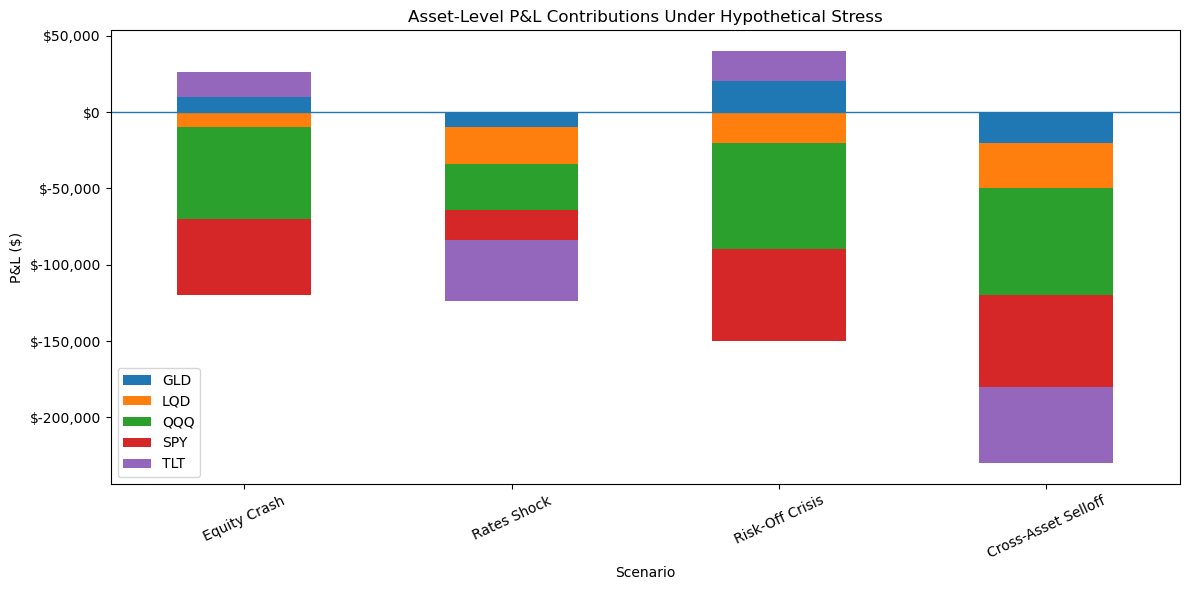

In [57]:
contribution_plot = (
    stress_contributions
    .set_index("Scenario")
    .drop(columns="Total P&L ($)")
)

contribution_plot.columns = [
    col.replace(" P&L ($)", "")
    for col in contribution_plot.columns
]

ax = contribution_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

ax.axhline(
    0,
    linewidth=1
)

ax.set_title(
    "Asset-Level P&L Contributions Under Hypothetical Stress"
)

ax.set_ylabel(
    "P&L ($)"
)

ax.set_xlabel(
    "Scenario"
)

ax.tick_params(
    axis="x",
    rotation=25
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"${x:,.0f}"
    )
)

plt.tight_layout()
plt.show()

## 16. Model Limitations and Risk Management Implications

The analysis demonstrates that no single measure provides a complete description of portfolio tail risk.

### Model Risk

Historical VaR is non-parametric and captures the empirical return distribution, but it is backward-looking and cannot represent market states absent from the estimation window. Gaussian VaR is computationally simple, yet the empirical results show that normality is inadequate for a portfolio with heavy tails and volatility clustering.

EWMA improves responsiveness to changing volatility, but Gaussian EWMA still fails formal coverage tests. Rolling Student-t EWMA explicitly allows heavier conditional tails and improves on Gaussian EWMA, but it also fails conditional coverage in this sample.

### Exception Clustering

The Christoffersen results show that VaR exceptions are not independent through time. A model can therefore appear reasonably calibrated on average while still producing clusters of breaches during stressed regimes. This is particularly important from a risk-management perspective because model weakness becomes most consequential when losses are already elevated.

### Diversification Risk

The stress tests demonstrate that diversification is regime-dependent. Gold and long-duration Treasuries provide meaningful offsets in several equity-driven scenarios, but this protection cannot be assumed to persist. Episodes in which equities and fixed income decline together can materially increase portfolio losses.

### Practical Implication

VaR should not be used in isolation. A more complete market-risk framework combines VaR with Expected Shortfall, drawdown analysis, formal backtesting, dynamic volatility monitoring, and historical and hypothetical stress testing.


## 17. Conclusion

This project develops an end-to-end market-risk framework for a multi-asset portfolio using empirical and parametric tail-risk measures, Monte Carlo simulation, dynamic volatility modelling, formal model validation, and scenario analysis.

The central result is that greater model complexity does not automatically imply better risk measurement. Historical VaR achieves the strongest unconditional coverage in the sample, while Gaussian specifications materially underestimate extreme risk. EWMA reacts faster to volatility changes, and Student-t innovations improve the representation of heavy tails, yet clustered exceptions remain a persistent challenge.

Stress testing provides a complementary perspective by showing how portfolio resilience depends on cross-asset behaviour. Defensive exposures can materially reduce losses in conventional equity-driven crises, but their protection weakens when equities and fixed income experience simultaneous losses.

Overall, the project illustrates why effective market-risk management requires multiple complementary tools and continual model validation rather than reliance on a single VaR estimate or distributional assumption.


## Technical Summary

- **Portfolio:** $1,000,000 notional, equally weighted across GLD, LQD, QQQ, SPY and TLT.
- **Sample:** Daily adjusted market data from 2010 through July 2026.
- **Risk measures:** Historical, Gaussian and Monte Carlo VaR/Expected Shortfall at 95% and 99%.
- **Dynamic models:** Rolling Gaussian VaR, EWMA Gaussian VaR, and rolling Student-t EWMA VaR.
- **Validation:** Kupiec unconditional-coverage test, Christoffersen independence test, and conditional-coverage test.
- **Key backtesting result:** Historical 99% VaR produces the closest unconditional exception rate to the theoretical 1% target, but no tested model passes conditional coverage.
- **Stress testing:** Historical crisis scenarios, hypothetical cross-asset shocks, and asset-level P&L attribution.
- **Key modelling lesson:** Tail risk reflects both time-varying volatility and non-Gaussian returns; diversification itself is also regime-dependent.
